In [1]:
import os
import sys
import jax

In [2]:
sys.path.append('../../')

In [3]:
from modules.gt_tree_gen import *
from modules.vis_utils import *
from modules.tree_func import *
from modules.catalan_tools import *
from modules.sankoff import *

In [4]:
metadata = {
            'n_mutations':5,
            'n_all': 31,
            'n_leaves': 16,
            'n_ancestors':15,
    
            'seq_length':10,
            'n_letters':5,
            }

n_leaves = metadata['n_leaves']
n_mutations = metadata['n_mutations']

seq, __, original_adj = generate_general_groundtruth(metadata, seed = 42)
# _,__, adj = generate_groundtruth(metadata, seed = 3)
seq,__,original_adj



Explicitly requested dtype <class 'jax.numpy.int64'> requested in zeros is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.


(Array([[4, 0, 1, 0, 0, 2, 0, 3, 3, 0],
        [2, 3, 0, 3, 4, 4, 1, 1, 3, 0],
        [1, 4, 4, 3, 2, 1, 1, 1, 3, 0],
        [1, 0, 4, 3, 0, 1, 3, 2, 2, 4],
        [0, 2, 4, 1, 2, 3, 1, 3, 2, 3],
        [0, 2, 0, 1, 3, 1, 0, 1, 4, 0],
        [4, 1, 1, 4, 0, 3, 0, 0, 1, 1],
        [2, 2, 2, 3, 0, 1, 0, 0, 3, 0],
        [1, 2, 2, 0, 0, 3, 2, 0, 4, 4],
        [4, 3, 4, 3, 4, 2, 0, 3, 0, 4],
        [2, 3, 2, 2, 2, 0, 0, 0, 1, 2],
        [2, 4, 3, 0, 4, 4, 0, 2, 0, 1],
        [0, 1, 3, 2, 4, 0, 0, 0, 2, 1],
        [0, 2, 1, 2, 4, 3, 3, 2, 1, 4],
        [2, 0, 0, 2, 0, 2, 2, 1, 1, 1],
        [3, 1, 1, 2, 4, 0, 3, 1, 3, 1],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],


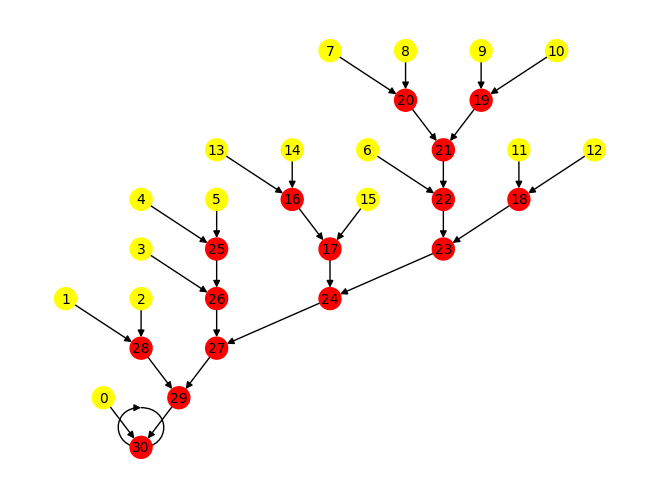

In [5]:
show_graph_with_labels(original_adj, n_leaves, return_img = True)

In [6]:
seq.shape

(31, 10)

In [7]:
seq[:n_leaves]

Array([[4, 0, 1, 0, 0, 2, 0, 3, 3, 0],
       [2, 3, 0, 3, 4, 4, 1, 1, 3, 0],
       [1, 4, 4, 3, 2, 1, 1, 1, 3, 0],
       [1, 0, 4, 3, 0, 1, 3, 2, 2, 4],
       [0, 2, 4, 1, 2, 3, 1, 3, 2, 3],
       [0, 2, 0, 1, 3, 1, 0, 1, 4, 0],
       [4, 1, 1, 4, 0, 3, 0, 0, 1, 1],
       [2, 2, 2, 3, 0, 1, 0, 0, 3, 0],
       [1, 2, 2, 0, 0, 3, 2, 0, 4, 4],
       [4, 3, 4, 3, 4, 2, 0, 3, 0, 4],
       [2, 3, 2, 2, 2, 0, 0, 0, 1, 2],
       [2, 4, 3, 0, 4, 4, 0, 2, 0, 1],
       [0, 1, 3, 2, 4, 0, 0, 0, 2, 1],
       [0, 2, 1, 2, 4, 3, 3, 2, 1, 4],
       [2, 0, 0, 2, 0, 2, 2, 1, 1, 1],
       [3, 1, 1, 2, 4, 0, 3, 1, 3, 1]], dtype=int32)

In [8]:
population = 5000

In [9]:
hashmap = generate_random_tree_distribution(n_leaves, population, verbose = False)

In [10]:
len(hashmap.keys())

4980

In [11]:
cost_mat = jnp.ones((metadata['n_letters'],metadata['n_letters'])) - jnp.identity(metadata['n_letters']).astype(jnp.float32)

In [12]:
cost_freq = {}


for tree in hashmap.keys():
    print(".", end = "")
    
    adj, _ = convert_parenthesis_notation_to_adj_matrix(tree)
    _, _, cost = run_sankoff(adj, cost_mat, seq, metadata, return_path = False)
    
    if(str(cost) not in cost_freq.keys()):
        cost_freq[str(cost)] = 1
    else:
        cost_freq[str(cost)] += 1

.
Explicitly requested dtype <class 'jax.numpy.float64'> requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.


........................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................

In [13]:
len(cost_freq.keys())

16

In [14]:
cost_freq

{'86.0': 835,
 '88.0': 819,
 '87.0': 941,
 '85.0': 650,
 '84.0': 379,
 '89.0': 554,
 '91.0': 155,
 '90.0': 292,
 '83.0': 163,
 '94.0': 8,
 '81.0': 21,
 '92.0': 71,
 '82.0': 56,
 '93.0': 31,
 '80.0': 4,
 '97.0': 1}

In [15]:
frequencies = list(cost_freq.values())
frequencies

[835, 819, 941, 650, 379, 554, 155, 292, 163, 8, 21, 71, 56, 31, 4, 1]

In [16]:
key_lis = list(cost_freq.keys())
costs = list(map(float, key_lis))

In [22]:
len(set(costs))

16

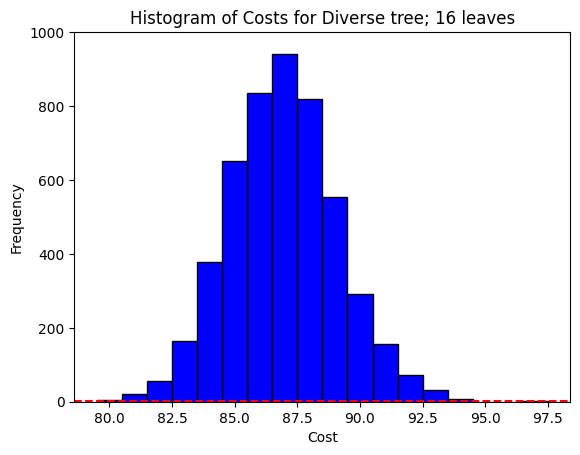

In [20]:
# Create the histogram
plt.bar(costs, frequencies, width=1, color='b', edgecolor='black')

# Adding labels and title
plt.axhline(y = 1, color='r', linestyle='--')

plt.ylim(0,1000)
plt.xlabel('Cost')
plt.ylabel('Frequency')
plt.title(f'Histogram of Costs for Diverse tree; {n_leaves} leaves')
plt.savefig(f"diverse_{n_leaves}_{len(hashmap.keys())}.png")

In [18]:
_, _, cost = run_sankoff(original_adj, cost_mat, seq, metadata, return_path = False)
cost

Array(84., dtype=float32)